In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [3]:
CSV_PATH = "fashion-mnist_train.csv"
TARGET_COLUMN = "label"

fashion_df = pd.read_csv(CSV_PATH)

print("Dataset shape:", fashion_df.shape)
display(fashion_df.head(10))
print("\nClass distribution:")
print(fashion_df[TARGET_COLUMN].value_counts().sort_index())

Dataset shape: (39733, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,9,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,6,0,0,0,0,0,0,0,5,0,...,0.0,0.0,0.0,30.0,43.0,0.0,0.0,0.0,0.0,0.0
3,0,0,0,0,1,2,0,0,0,0,...,3.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,3,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,4,0,0,0,5,4,5,5,3,5,...,7.0,8.0,7.0,4.0,3.0,7.0,5.0,0.0,0.0,0.0
6,4,0,0,0,0,0,0,0,0,0,...,14.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,5,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,4,0,0,0,0,0,0,3,2,0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,8,0,0,0,0,0,0,0,0,0,...,203.0,214.0,166.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Class distribution:
label
0    3937
1    3969
2    3938
3    3982
4    3930
5    3991
6    4029
7    3988
8    3988
9    3981
Name: count, dtype: int64


In [4]:
X = fashion_df.drop(columns=[TARGET_COLUMN]).astype("float32")
y = fashion_df[TARGET_COLUMN]
X = X.dropna()
X_normalized = X / 255.0

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_normalized)

print("Original feature count:", X.shape[1])
print("Scaled data shape:", X_scaled.shape)

Original feature count: 784
Scaled data shape: (39732, 784)


In [5]:
# Method 1: fixed 50 components
pca_50 = PCA(n_components=50, svd_solver="randomized", random_state=42)
X_pca_50 = pca_50.fit_transform(X_scaled)

# Method 2: retain at least 95% of variance
pca_95 = PCA(n_components=0.95, svd_solver="full")
X_pca_95 = pca_95.fit_transform(X_scaled)

# Method 3: retain all components
pca_all = PCA(n_components=None, svd_solver="full")
X_pca_all = pca_all.fit_transform(X_scaled)

results_pca = pd.DataFrame([
    {
        "Method": "Fixed 50",
        "Original features": X.shape[1],
        "Retained components": pca_50.n_components_,
        "Cumulative explained variance": pca_50.explained_variance_ratio_.sum()
    },
    {
        "Method": "95% variance",
        "Original features": X.shape[1],
        "Retained components": pca_95.n_components_,
        "Cumulative explained variance": pca_95.explained_variance_ratio_.sum()
    },
    {
        "Method": "All components",
        "Original features": X.shape[1],
        "Retained components": pca_all.n_components_,
        "Cumulative explained variance": pca_all.explained_variance_ratio_.sum()
    }
])
display(results_pca.style.format({"Cumulative explained variance": "{:.2%}"}))

,Method,Original features,Retained components,Cumulative explained variance
0,Fixed 50,784,50,79.98%
1,95% variance,784,254,95.01%
2,All components,784,784,100.00%


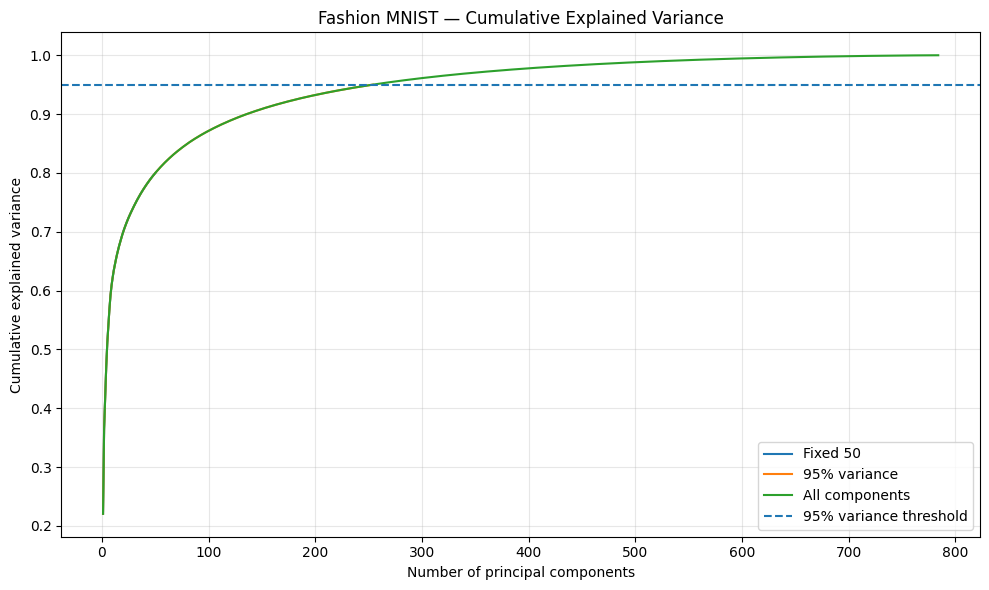

In [6]:
plt.figure(figsize=(10, 6))
for label, model in [
    ("Fixed 50", pca_50),
    ("95% variance", pca_95),
    ("All components", pca_all)
]:
    cumulative = np.cumsum(model.explained_variance_ratio_)
    plt.plot(np.arange(1, len(cumulative) + 1), cumulative, label=label)

plt.axhline(0.95, linestyle="--", label="95% variance threshold")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("Fashion MNIST — Cumulative Explained Variance")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

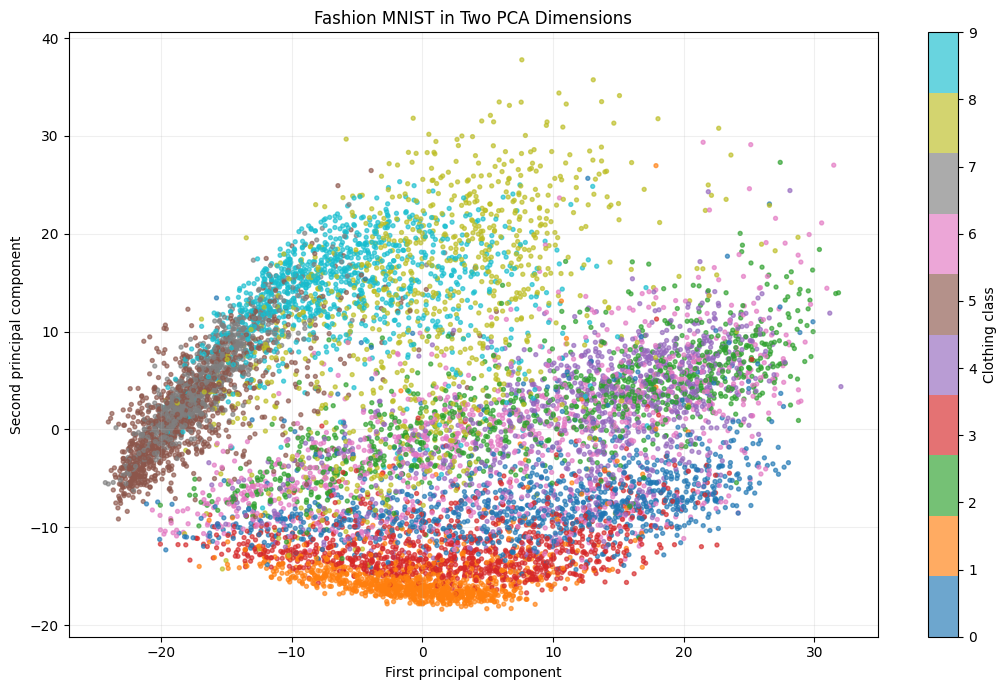

Variance explained by the two plotted components: 36.75%


In [7]:
# Use the first two components from a separate 2-component PCA.
# Sample up to 10,000 rows for a clearer, faster plot.
rng = np.random.RandomState(42)
sample_size = min(10000, len(X_scaled))
sample_idx = rng.choice(len(X_scaled), size=sample_size, replace=False)

pca_2d = PCA(n_components=2, svd_solver="randomized", random_state=42)
X_2d = pca_2d.fit_transform(X_scaled[sample_idx])

plt.figure(figsize=(11, 7))
scatter = plt.scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=y.iloc[sample_idx].to_numpy(),
    cmap="tab10", s=8, alpha=0.65
)
plt.xlabel("First principal component")
plt.ylabel("Second principal component")
plt.title("Fashion MNIST in Two PCA Dimensions")
plt.colorbar(scatter, label="Clothing class")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Variance explained by the two plotted components:",
      f"{pca_2d.explained_variance_ratio_.sum():.2%}")

In [8]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

In [9]:
HEART_CSV_PATH = "heart.csv"
heart_df = pd.read_csv(HEART_CSV_PATH)

print("Dataset shape:", heart_df.shape)
display(heart_df.head(10))
print("\nMissing values per column:")
print(heart_df.isnull().sum())
print("\nColumns:", heart_df.columns.tolist())

possible_targets = ["target", "HeartDisease", "heart_disease", "output", "num"]
TARGET_COLUMN = next((c for c in possible_targets if c in heart_df.columns), None)
if TARGET_COLUMN is None:
    raise ValueError(
        "Target column not detected. Set TARGET_COLUMN to the correct target column "
        "name from heart_df.columns."
    )

print("\nUsing target column:", TARGET_COLUMN)
print("Target distribution:")
print(heart_df[TARGET_COLUMN].value_counts(dropna=False))

Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
5,57,1,0,140,192,0,1,148,0,0.4,1,0,1,1
6,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1
7,44,1,1,120,263,0,1,173,0,0.0,2,0,3,1
8,52,1,2,172,199,1,1,162,0,0.5,2,0,3,1
9,57,1,2,150,168,0,1,174,0,1.6,2,0,2,1



Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Using target column: target
Target distribution:
target
1    165
0    138
Name: count, dtype: int64


In [10]:
X = heart_df.drop(columns=[TARGET_COLUMN]).copy()
y = heart_df[TARGET_COLUMN].copy()

# Remove common identifier columns if present.
id_columns = [c for c in X.columns if c.lower() in {"id", "patient_id", "patientid"}]
X = X.drop(columns=id_columns)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training class distribution:")
print(y_train.value_counts(normalize=True))

Training rows: 242
Testing rows: 61
Training class distribution:
target
1    0.545455
0    0.454545
Name: proportion, dtype: float64


In [11]:
baseline_clf = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

baseline_clf.fit(X_train, y_train)
baseline_pred = baseline_clf.predict(X_test)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("Baseline test accuracy:", round(baseline_accuracy, 4))

Baseline test accuracy: 0.8361


In [12]:
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt", "log2"]
}

grid_clf = GridSearchCV(
    estimator=Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(random_state=42))
    ]),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_clf.fit(X_train, y_train)

print("Best parameters:")
print(grid_clf.best_params_)
print("Best cross-validation accuracy:", round(grid_clf.best_score_, 4))

best_clf = grid_clf.best_estimator_
best_pred = best_clf.predict(X_test)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best parameters:
{'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best cross-validation accuracy: 0.8391


Test accuracy:  0.8525
Weighted precision: 0.8699
Weighted recall:    0.8525
Weighted F1-score:  0.8490

Classification report:
              precision    recall  f1-score   support

           0       0.95      0.71      0.82        28
           1       0.80      0.97      0.88        33

    accuracy                           0.85        61
   macro avg       0.88      0.84      0.85        61
weighted avg       0.87      0.85      0.85        61



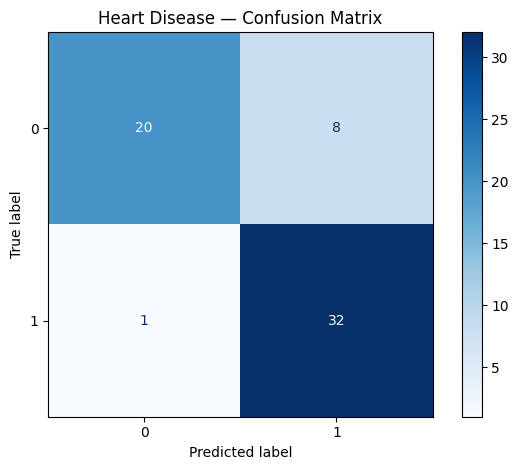

In [13]:
accuracy = accuracy_score(y_test, best_pred)
precision = precision_score(y_test, best_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, best_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, best_pred, average="weighted", zero_division=0)

print(f"Test accuracy:  {accuracy:.4f}")
print(f"Weighted precision: {precision:.4f}")
print(f"Weighted recall:    {recall:.4f}")
print(f"Weighted F1-score:  {f1:.4f}")
print("\nClassification report:")
print(classification_report(y_test, best_pred, zero_division=0))

labels = best_clf.named_steps["model"].classes_
cm = confusion_matrix(y_test, best_pred, labels=labels)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(cmap="Blues")
plt.title("Heart Disease — Confusion Matrix")
plt.tight_layout()
plt.show()

,Feature,Importance
2,numeric__cp,0.175162
7,numeric__thalach,0.119497
12,numeric__thal,0.116169
9,numeric__oldpeak,0.111292
11,numeric__ca,0.085353
4,numeric__chol,0.078575
0,numeric__age,0.070966
10,numeric__slope,0.065775
8,numeric__exang,0.063926
3,numeric__trestbps,0.058005


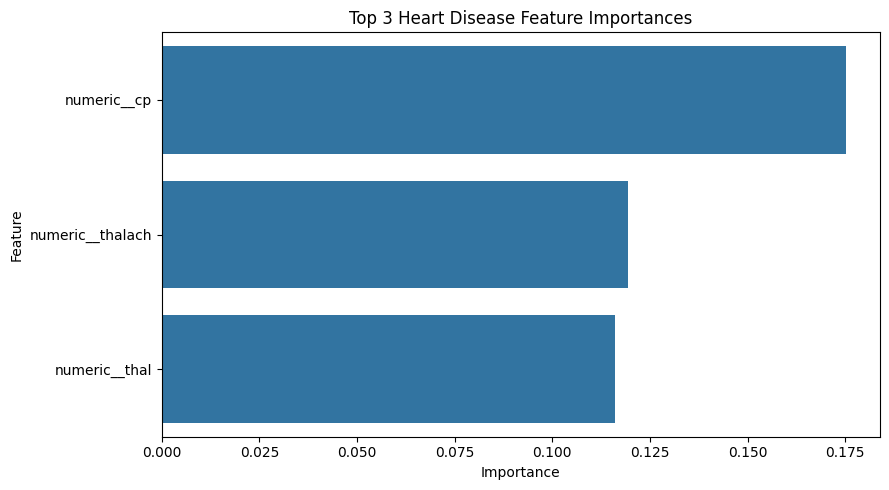

,Model,Test accuracy
0,Baseline Random Forest,0.8361
1,GridSearchCV optimized,0.8525


In [14]:
fitted_preprocessor = best_clf.named_steps["preprocessor"]
fitted_model = best_clf.named_steps["model"]
encoded_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": encoded_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(10))

top3 = importance_df.head(3)
plt.figure(figsize=(9, 5))
sns.barplot(data=top3, x="Importance", y="Feature")
plt.title("Top 3 Heart Disease Feature Importances")
plt.tight_layout()
plt.show()

comparison_clf = pd.DataFrame([
    {"Model": "Baseline Random Forest", "Test accuracy": baseline_accuracy},
    {"Model": "GridSearchCV optimized", "Test accuracy": accuracy}
])
display(comparison_clf.style.format({"Test accuracy": "{:.4f}"}))

In [15]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


HOUSE_CSV_PATH = "Housing.csv"
house_df = pd.read_csv(HOUSE_CSV_PATH)

print("Dataset shape:", house_df.shape)
display(house_df.head(10))
print("\nMissing values (columns with missing data):")
print(house_df.isnull().sum()[house_df.isnull().sum() > 0].sort_values(ascending=False))
print("\nSalePrice summary:")
print(house_df["price"].describe())

Dataset shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
5,10850000,7500,3,3,1,yes,no,yes,no,yes,2,yes,semi-furnished
6,10150000,8580,4,3,4,yes,no,no,no,yes,2,yes,semi-furnished
7,10150000,16200,5,3,2,yes,no,no,no,no,0,no,unfurnished
8,9870000,8100,4,1,2,yes,yes,yes,no,yes,2,yes,furnished
9,9800000,5750,3,2,4,yes,yes,no,no,yes,1,yes,unfurnished



Missing values (columns with missing data):
Series([], dtype: int64)

SalePrice summary:
count    5.450000e+02
mean     4.766729e+06
std      1.870440e+06
min      1.750000e+06
25%      3.430000e+06
50%      4.340000e+06
75%      5.740000e+06
max      1.330000e+07
Name: price, dtype: float64


In [16]:
X = house_df.drop(columns=["price"], errors="ignore").copy()
y = house_df["price"].copy()

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

house_preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 436
Testing rows: 109


In [17]:
baseline_reg = Pipeline([
    ("preprocessor", house_preprocessor),
    ("model", RandomForestRegressor(random_state=42))
])

baseline_reg.fit(X_train, y_train)
baseline_pred = baseline_reg.predict(X_test)

def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred)
    }

baseline_metrics = regression_metrics(y_test, baseline_pred)
print("Baseline test metrics:")
for metric, value in baseline_metrics.items():
    print(f"{metric}: {value:,.4f}")

Baseline test metrics:
MAE: 1,025,824.3794
MSE: 1,971,426,095,653.9329
RMSE: 1,404,074.8184
R2: 0.6100


In [18]:
param_grid_reg = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": [0.7, 1.0]
}

grid_reg = GridSearchCV(
    estimator=Pipeline([
        ("preprocessor", house_preprocessor),
        ("model", RandomForestRegressor(random_state=42))
    ]),
    param_grid=param_grid_reg,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

grid_reg.fit(X_train, y_train)

best_cv_mse = -grid_reg.best_score_
best_cv_rmse = np.sqrt(best_cv_mse)

print("Best parameters:")
print(grid_reg.best_params_)
print("Best cross-validation MSE:", f"{best_cv_mse:,.2f}")
print("Best cross-validation RMSE:", f"{best_cv_rmse:,.2f}")

best_reg = grid_reg.best_estimator_
best_pred = best_reg.predict(X_test)
best_metrics = regression_metrics(y_test, best_pred)

print("\nOptimized model test metrics:")
for metric, value in best_metrics.items():
    print(f"{metric}: {value:,.4f}")

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best parameters:
{'model__max_depth': 10, 'model__max_features': 0.7, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best cross-validation MSE: 1,142,177,393,374.71
Best cross-validation RMSE: 1,068,727.00

Optimized model test metrics:
MAE: 1,039,394.5843
MSE: 1,965,944,605,339.1519
RMSE: 1,402,121.4660
R2: 0.6111


In [19]:
comparison_reg = pd.DataFrame([
    {"Model": "Default Random Forest", **baseline_metrics},
    {"Model": "GridSearchCV optimized", **best_metrics}
])
display(comparison_reg.style.format({
    "MAE": "{:,.2f}", "MSE": "{:,.2f}",
    "RMSE": "{:,.2f}", "R2": "{:.4f}"
}))

,Model,MAE,MSE,RMSE,R2
0,Default Random Forest,"1,025,824.38","1,971,426,095,653.93","1,404,074.82",0.6100
1,GridSearchCV optimized,"1,039,394.58","1,965,944,605,339.15","1,402,121.47",0.6111


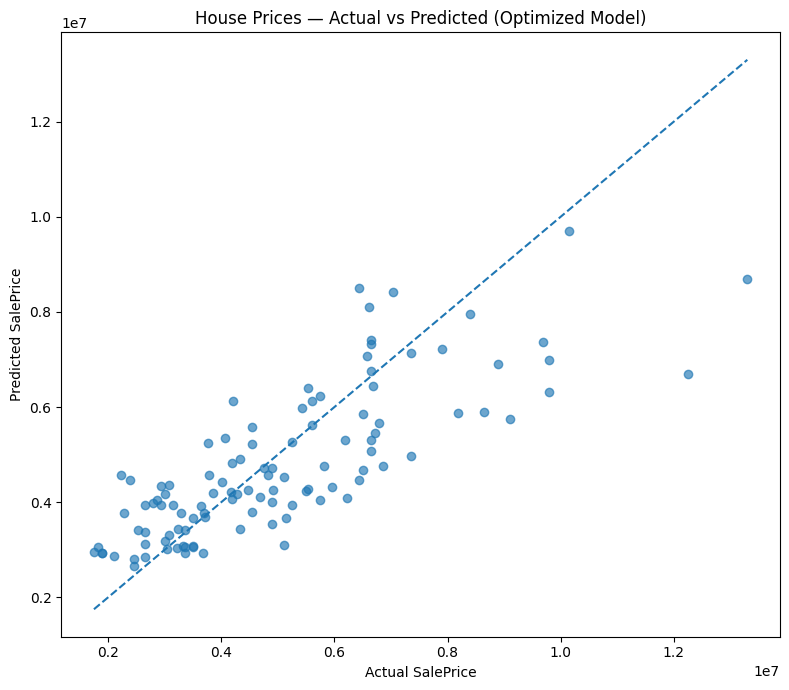

In [20]:
plt.figure(figsize=(8, 7))
plt.scatter(y_test, best_pred, alpha=0.65)
min_price = min(float(y_test.min()), float(np.min(best_pred)))
max_price = max(float(y_test.max()), float(np.max(best_pred)))
plt.plot([min_price, max_price], [min_price, max_price], linestyle="--")
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("House Prices — Actual vs Predicted (Optimized Model)")
plt.tight_layout()
plt.show()

,Feature,Importance
0,numeric__area,0.425050
2,numeric__bathrooms,0.167479
3,numeric__stories,0.052468
13,categorical__airconditioning_no,0.048240
4,numeric__parking,0.047826


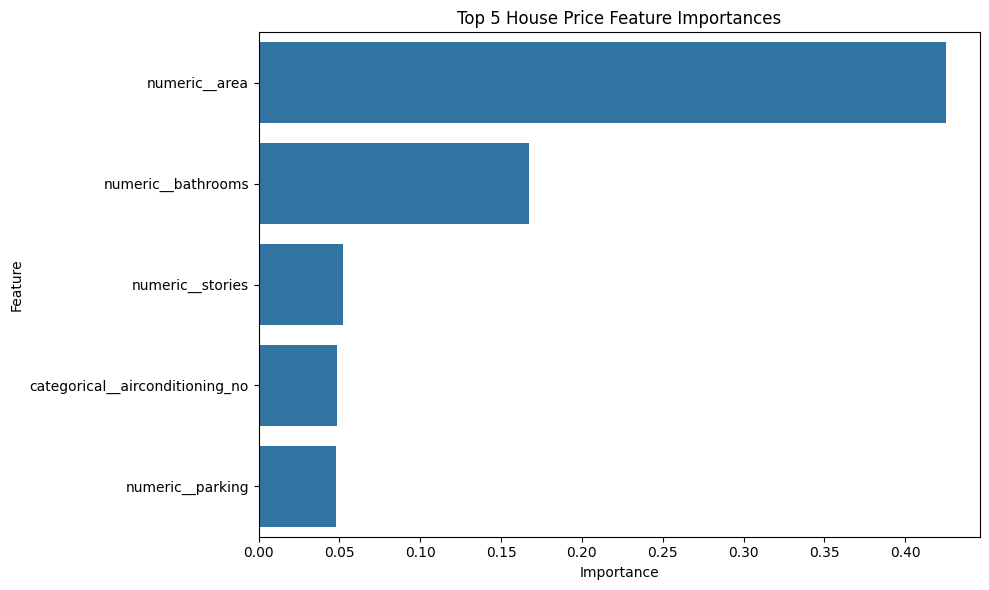

In [21]:
fitted_house_preprocessor = best_reg.named_steps["preprocessor"]
fitted_house_model = best_reg.named_steps["model"]
house_feature_names = fitted_house_preprocessor.get_feature_names_out()

house_importance_df = pd.DataFrame({
    "Feature": house_feature_names,
    "Importance": fitted_house_model.feature_importances_
}).sort_values("Importance", ascending=False)

top5_house = house_importance_df.head(5)
display(top5_house)

plt.figure(figsize=(10, 6))
sns.barplot(data=top5_house, x="Importance", y="Feature")
plt.title("Top 5 House Price Feature Importances")
plt.tight_layout()
plt.show()